# Team I3 — All Model Training (Deep Learning + Hybrid)

**Standalone Mean-life and Elastic-Net baseline training are intentionally excluded.**

Included experiments:
- 1D CNN at 10-, 30-, and 100-cycle horizons.
- 2D CNN at the 100-cycle horizon.
- Temporal-attention 1D CNN at 10, 30, and 100 cycles.
- No-attention ablation at 10, 30, and 100 cycles.
- Optional CNN + Elastic-Net prediction fusion (loads Elastic-Net artifacts created by `baselines.ipynb`; it does not train the standalone baseline).

Run the preprocessing notebook first. For the core CNN experiments only, run through the 2D CNN section. The attention, ablation, and fusion sections are optional extensions.

Expected files: `data/processed/normalized_{horizon}_{split}.npz` with keys `delta`, `summary`, `image`, `y`, `ids`.

In [1]:
from pathlib import Path
import copy, random, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")

In [2]:
PROJECT_ROOT = Path(r"C:\Users\lokan\Document\DL\ENDSEM")
PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"
RESULT_ROOT = PROJECT_ROOT / "results" / "deep_learning"
BASELINE_ROOT = PROJECT_ROOT / "results" / "baselines"
RESULT_ROOT.mkdir(parents=True, exist_ok=True)

HORIZONS, SPLITS = [10, 30, 100], ["train", "val", "test"]
SEED, EPOCHS, BATCH_SIZE = 22, 300, 16
LEARNING_RATE, WEIGHT_DECAY, PATIENCE = 1e-3, 1e-5, 35
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
print("Device:", DEVICE)

Device: cpu


In [3]:
def load_npz(h, s):
    path = PROCESSED_ROOT / f"normalized_{h}_{s}.npz"
    if not path.exists(): raise FileNotFoundError(path)
    with np.load(path, allow_pickle=True) as z:
        needed = {"delta", "summary", "image", "y", "ids"}
        missing = needed - set(z.files)
        if missing: raise KeyError(f"{path.name} missing {missing}")
        return {
            "delta": np.asarray(z["delta"], np.float32),
            "summary": np.asarray(z["summary"], np.float32),
            "image": np.asarray(z["image"], np.float32),
            "y": np.asarray(z["y"], np.float32).reshape(-1),
            "ids": np.asarray(z["ids"]).astype(str)
        }

DATA = {h: {s: load_npz(h, s) for s in SPLITS} for h in HORIZONS}
for h in HORIZONS:
    for s in SPLITS:
        d = DATA[h][s]
        n = len(d["y"])
        assert all(len(d[k]) == n for k in ["delta", "summary", "image", "ids"])
        for k in ["delta", "summary", "image", "y"]:
            if not np.isfinite(d[k]).all():
                raise ValueError(f"Non-finite {k} values in horizon={h}, split={s}")
        if (d["y"] <= 0).any(): raise ValueError("Targets must be positive.")
        print(h, s, "delta", d["delta"].shape, "summary", d["summary"].shape,
              "image", d["image"].shape, "y", d["y"].shape)

10 train delta (75, 1000) summary (75, 10, 6) image (75, 1, 10, 1000) y (75,)
10 val delta (24, 1000) summary (24, 10, 6) image (24, 1, 10, 1000) y (24,)
10 test delta (29, 1000) summary (29, 10, 6) image (29, 1, 10, 1000) y (29,)
30 train delta (75, 1000) summary (75, 30, 6) image (75, 1, 30, 1000) y (75,)
30 val delta (24, 1000) summary (24, 30, 6) image (24, 1, 30, 1000) y (24,)
30 test delta (29, 1000) summary (29, 30, 6) image (29, 1, 30, 1000) y (29,)
100 train delta (75, 1000) summary (75, 100, 6) image (75, 1, 100, 1000) y (75,)
100 val delta (24, 1000) summary (24, 100, 6) image (24, 1, 100, 1000) y (24,)
100 test delta (29, 1000) summary (29, 100, 6) image (29, 1, 100, 1000) y (29,)


## 1. Dataset, metrics, and training engine

Models learn log(cycle life). Validation RMSE in original cycle units selects the checkpoint. The test split is used only after training is complete.

In [4]:
class BatteryDataset(Dataset):
    def __init__(self, d, image=False):
        self.delta = torch.tensor(d["delta"], dtype=torch.float32)
        self.summary = torch.tensor(d["summary"], dtype=torch.float32)
        self.image = torch.tensor(d["image"], dtype=torch.float32)
        self.ylog = torch.tensor(np.log(d["y"]), dtype=torch.float32)
        self.use_image = image
    def __len__(self): return len(self.ylog)
    def __getitem__(self, i):
        if self.use_image:
            return self.image[i], self.ylog[i]
        return self.delta[i], self.summary[i], self.ylog[i]

def loader(d, shuffle=False, image=False):
    return DataLoader(BatteryDataset(d, image), batch_size=BATCH_SIZE,
                      shuffle=shuffle, num_workers=0,
                      pin_memory=(DEVICE.type == "cuda"))

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "MAPE_percent": float(np.mean(np.abs((y-p)/y))*100),
            "R2": r2_score(y, p)}

def predict(model, dl, kind="standard"):
    model.eval(); pred, actual = [], []
    with torch.no_grad():
        for batch in dl:
            if kind == "image":
                x, yt = batch
                out = model(x.to(DEVICE))
            else:
                xd, xs, yt = batch
                out = model(xd.to(DEVICE), xs.to(DEVICE))
            pred.extend(out.cpu().numpy().reshape(-1))
            actual.extend(yt.numpy().reshape(-1))
    return np.exp(np.asarray(actual)), np.exp(np.clip(np.asarray(pred), -20, 20))

def train(model, h, name, kind="standard"):
    model.to(DEVICE)
    tr = loader(DATA[h]["train"], shuffle=True, image=(kind=="image"))
    va = loader(DATA[h]["val"], image=(kind=="image"))
    opt = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE,
                           weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=0.5, patience=10)
    loss_fn = nn.MSELoss()
    best_rmse, best_state, best_epoch, wait = np.inf, None, 0, 0
    history = []

    for epoch in range(1, EPOCHS+1):
        model.train(); losses=[]
        for batch in tr:
            opt.zero_grad()
            if kind == "image":
                x, yt = batch; out = model(x.to(DEVICE)); target=yt.to(DEVICE)
            else:
                xd, xs, yt = batch
                out = model(xd.to(DEVICE), xs.to(DEVICE)); target=yt.to(DEVICE)
            loss = loss_fn(out.reshape(-1), target.reshape(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step(); losses.append(loss.item())

        yv, pv = predict(model, va, kind)
        vm = metrics(yv, pv); scheduler.step(vm["RMSE"])
        history.append({"epoch":epoch, "train_log_mse":float(np.mean(losses)),
                        "val_RMSE":vm["RMSE"], "val_MAE":vm["MAE"],
                        "learning_rate":opt.param_groups[0]["lr"]})
        if vm["RMSE"] < best_rmse:
            best_rmse, best_state, best_epoch, wait = vm["RMSE"], copy.deepcopy(model.state_dict()), epoch, 0
        else: wait += 1
        if epoch == 1 or epoch % 10 == 0:
            print(f"{name} epoch {epoch}: val RMSE={vm['RMSE']:.3f}")
        if wait >= PATIENCE:
            print("Early stopping. Best epoch:", best_epoch); break

    if best_state is None: raise RuntimeError("Training did not produce a checkpoint.")
    model.load_state_dict(best_state)
    torch.save({"model_state_dict":model.state_dict(), "best_epoch":best_epoch,
                "best_val_rmse":best_rmse, "model_name":name},
               RESULT_ROOT / f"{name}.pth")
    hist = pd.DataFrame(history)
    hist.to_csv(RESULT_ROOT / f"{name}_history.csv", index=False)
    plt.figure(figsize=(8,4))
    plt.plot(hist.epoch, hist.train_log_mse, label="Train log-MSE")
    plt.plot(hist.epoch, hist.val_RMSE, label="Validation RMSE (cycles)")
    plt.xlabel("Epoch"); plt.ylabel("Loss / RMSE"); plt.title(name)
    plt.legend(); plt.tight_layout()
    plt.savefig(RESULT_ROOT / f"{name}_training_curves.png", dpi=160)
    plt.show()
    print(f"Saved {name}: best epoch={best_epoch}, validation RMSE={best_rmse:.3f}")
    return model

def test_and_save(model, h, name, kind="standard"):
    dl = loader(DATA[h]["test"], image=(kind=="image"))
    y, p = predict(model, dl, kind)
    pd.DataFrame({"sample_id":DATA[h]["test"]["ids"], "y_true":y,
                  "y_pred":p, "residual":y-p}).to_csv(
        RESULT_ROOT / f"{name}_{h}_test_predictions.csv", index=False)
    return metrics(y,p)

## 2. 1D CNN — 10, 30, and 100 cycles

The ΔQ(V) convolutional branch learns curve morphology. The temporal branch encodes the six per-cycle summary features and mean-pools over observed cycles.

In [5]:
class CNN1D(nn.Module):
    def __init__(self, n_summary=6):
        super().__init__()
        self.curve = nn.Sequential(
            nn.Conv1d(1,16,7,padding=3), nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16,32,5,padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32,64,3,padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten())
        self.temporal = nn.Sequential(nn.Linear(n_summary,32), nn.ReLU(),
                                      nn.Linear(32,64), nn.ReLU())
        self.head = nn.Sequential(nn.Linear(128,128), nn.ReLU(), nn.Dropout(.25),
                                  nn.Linear(128,32), nn.ReLU(), nn.Linear(32,1))
    def forward(self, delta, summary):
        a = self.curve(delta.unsqueeze(1))
        b = self.temporal(summary).mean(dim=1)
        return self.head(torch.cat([a,b], dim=1)).squeeze(1)


===== 1D CNN: 10 cycles =====
cnn_1d_10 epoch 1: val RMSE=961.975
cnn_1d_10 epoch 10: val RMSE=661.852
cnn_1d_10 epoch 20: val RMSE=495.776
cnn_1d_10 epoch 30: val RMSE=506.539
cnn_1d_10 epoch 40: val RMSE=478.239
cnn_1d_10 epoch 50: val RMSE=430.223
cnn_1d_10 epoch 60: val RMSE=476.929
cnn_1d_10 epoch 70: val RMSE=450.400
cnn_1d_10 epoch 80: val RMSE=456.390
Early stopping. Best epoch: 46


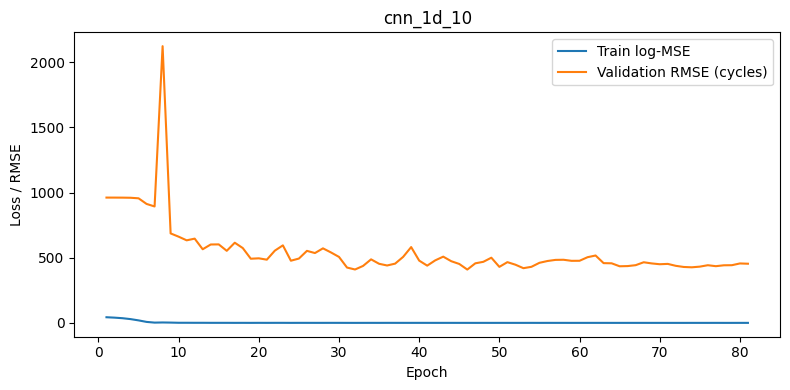

Saved cnn_1d_10: best epoch=46, validation RMSE=409.474

===== 1D CNN: 30 cycles =====
cnn_1d_30 epoch 1: val RMSE=962.080
cnn_1d_30 epoch 10: val RMSE=747.938
cnn_1d_30 epoch 20: val RMSE=453.359
cnn_1d_30 epoch 30: val RMSE=352.884
cnn_1d_30 epoch 40: val RMSE=445.417
cnn_1d_30 epoch 50: val RMSE=424.966
cnn_1d_30 epoch 60: val RMSE=374.645
cnn_1d_30 epoch 70: val RMSE=265.023
cnn_1d_30 epoch 80: val RMSE=247.111
cnn_1d_30 epoch 90: val RMSE=264.406
cnn_1d_30 epoch 100: val RMSE=261.160
cnn_1d_30 epoch 110: val RMSE=256.411
cnn_1d_30 epoch 120: val RMSE=266.496
cnn_1d_30 epoch 130: val RMSE=237.352
Early stopping. Best epoch: 96


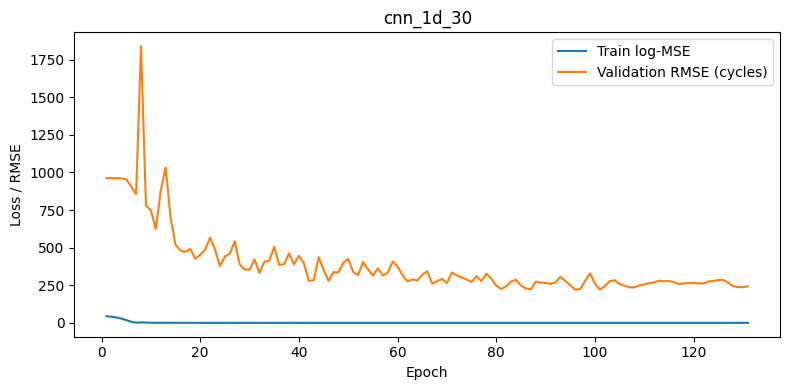

Saved cnn_1d_30: best epoch=96, validation RMSE=220.858

===== 1D CNN: 100 cycles =====
cnn_1d_100 epoch 1: val RMSE=961.780
cnn_1d_100 epoch 10: val RMSE=577.801
cnn_1d_100 epoch 20: val RMSE=391.925
cnn_1d_100 epoch 30: val RMSE=408.200
cnn_1d_100 epoch 40: val RMSE=411.583
cnn_1d_100 epoch 50: val RMSE=383.008
cnn_1d_100 epoch 60: val RMSE=298.037
Early stopping. Best epoch: 33


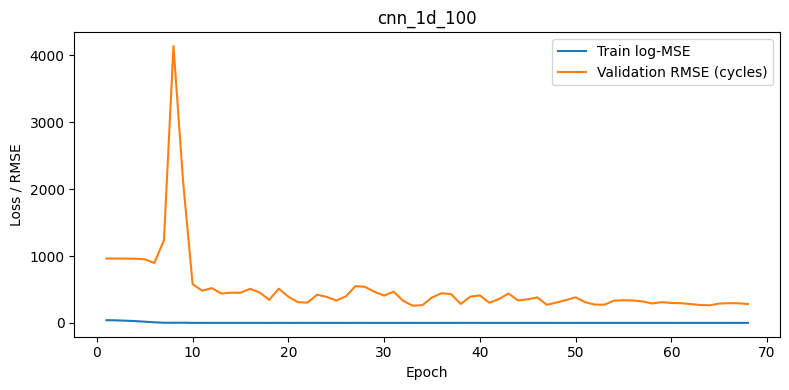

Saved cnn_1d_100: best epoch=33, validation RMSE=256.786


,model,horizon_cycles,MAE,RMSE,MAPE_percent,R2
0,1D CNN,10,186.730099,311.477791,20.318987,0.129838
1,1D CNN,30,112.181461,153.460604,14.373024,0.788778
2,1D CNN,100,162.930846,236.194481,20.311566,0.499637


In [6]:
cnn1d_models, cnn1d_rows = {}, []
for h in HORIZONS:
    print(f"\n===== 1D CNN: {h} cycles =====")
    model = CNN1D(DATA[h]["train"]["summary"].shape[-1])
    model = train(model, h, f"cnn_1d_{h}")
    cnn1d_models[h] = model
    result = test_and_save(model, h, f"cnn_1d_{h}")
    cnn1d_rows.append({"model":"1D CNN", "horizon_cycles":h, **result})

cnn1d_df = pd.DataFrame(cnn1d_rows)
cnn1d_df.to_csv(RESULT_ROOT / "cnn_1d_test_metrics.csv", index=False)
display(cnn1d_df)

## 3. 2D CNN — 100-cycle horizon

The input must have shape `(N, 1, 100, 1000)`: samples, channel, observed-cycle axis, and resampled voltage/capacity axis.

In [7]:
class CNN2D(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,16,3,padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.AdaptiveAvgPool2d((4,8)), nn.Flatten())
        self.head = nn.Sequential(nn.Linear(64*4*8,128), nn.ReLU(), nn.Dropout(.30),
                                  nn.Linear(128,64), nn.ReLU(), nn.Linear(64,1))
    def forward(self, image): return self.head(self.features(image)).squeeze(1)

2D input shape: (75, 1, 100, 1000)
cnn_2d_100 epoch 1: val RMSE=960.788
cnn_2d_100 epoch 10: val RMSE=663.267
cnn_2d_100 epoch 20: val RMSE=672.948
cnn_2d_100 epoch 30: val RMSE=397.475
cnn_2d_100 epoch 40: val RMSE=430.873
cnn_2d_100 epoch 50: val RMSE=483.785
cnn_2d_100 epoch 60: val RMSE=360.222
cnn_2d_100 epoch 70: val RMSE=411.740
Early stopping. Best epoch: 44


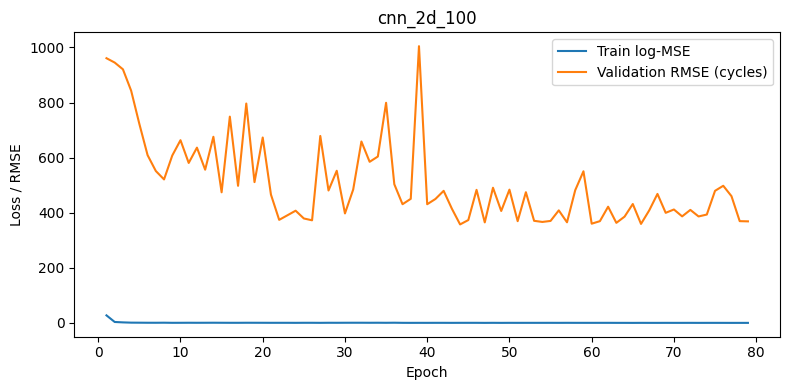

Saved cnn_2d_100: best epoch=44, validation RMSE=357.588


,model,horizon_cycles,MAE,RMSE,MAPE_percent,R2
0,2D CNN,100,226.940755,288.130965,33.54394,0.255395


In [8]:
xshape = DATA[100]["train"]["image"].shape
print("2D input shape:", xshape)
if len(xshape) != 4 or xshape[1:] != (1,100,1000):
    raise ValueError(f"Expected (N,1,100,1000), got {xshape}")

cnn2d = train(CNN2D(), 100, "cnn_2d_100", kind="image")
cnn2d_result = test_and_save(cnn2d, 100, "cnn_2d_100", kind="image")
cnn2d_df = pd.DataFrame([{"model":"2D CNN", "horizon_cycles":100, **cnn2d_result}])
cnn2d_df.to_csv(RESULT_ROOT / "cnn_2d_test_metrics.csv", index=False)
display(cnn2d_df)

## 4. Temporal-attention 1D CNN

The attention layer learns a weight for each observed cycle. The weighted temporal context replaces uniform mean pooling.

In [9]:
class TemporalAttentionCNN(nn.Module):
    def __init__(self, n_summary=6):
        super().__init__()
        self.curve = nn.Sequential(
            nn.Conv1d(1,16,7,padding=3), nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16,32,5,padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32,64,3,padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten())
        self.encoder = nn.Sequential(nn.Linear(n_summary,32), nn.ReLU(),
                                     nn.Linear(32,64), nn.Tanh())
        self.attention = nn.Linear(64,1)
        self.head = nn.Sequential(nn.Linear(128,128), nn.ReLU(), nn.Dropout(.25),
                                  nn.Linear(128,32), nn.ReLU(), nn.Linear(32,1))
    def forward(self, delta, summary, return_attention=False):
        a = self.curve(delta.unsqueeze(1))
        temporal = self.encoder(summary)
        weights = torch.softmax(self.attention(temporal).squeeze(-1), dim=1)
        context = torch.sum(temporal * weights.unsqueeze(-1), dim=1)
        out = self.head(torch.cat([a,context], dim=1)).squeeze(1)
        return (out,weights) if return_attention else out


===== Temporal attention: 10 cycles =====
temporal_attention_10 epoch 1: val RMSE=961.945
temporal_attention_10 epoch 10: val RMSE=704.194
temporal_attention_10 epoch 20: val RMSE=443.295
temporal_attention_10 epoch 30: val RMSE=495.661
temporal_attention_10 epoch 40: val RMSE=370.386
temporal_attention_10 epoch 50: val RMSE=323.121
temporal_attention_10 epoch 60: val RMSE=332.167
temporal_attention_10 epoch 70: val RMSE=399.435
temporal_attention_10 epoch 80: val RMSE=334.924
temporal_attention_10 epoch 90: val RMSE=355.854
temporal_attention_10 epoch 100: val RMSE=321.166
temporal_attention_10 epoch 110: val RMSE=346.526
temporal_attention_10 epoch 120: val RMSE=305.679
temporal_attention_10 epoch 130: val RMSE=311.982
Early stopping. Best epoch: 99


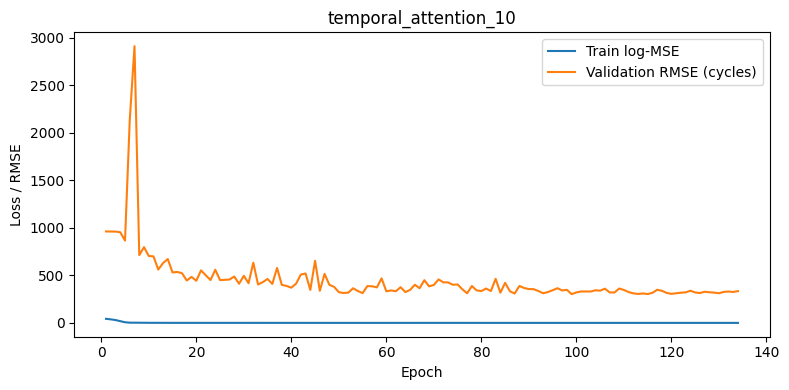

Saved temporal_attention_10: best epoch=99, validation RMSE=302.533

===== Temporal attention: 30 cycles =====
temporal_attention_30 epoch 1: val RMSE=961.788
temporal_attention_30 epoch 10: val RMSE=759.665
temporal_attention_30 epoch 20: val RMSE=421.644
temporal_attention_30 epoch 30: val RMSE=408.385
temporal_attention_30 epoch 40: val RMSE=440.234
temporal_attention_30 epoch 50: val RMSE=274.044
temporal_attention_30 epoch 60: val RMSE=353.057
temporal_attention_30 epoch 70: val RMSE=333.303
temporal_attention_30 epoch 80: val RMSE=270.114
Early stopping. Best epoch: 54


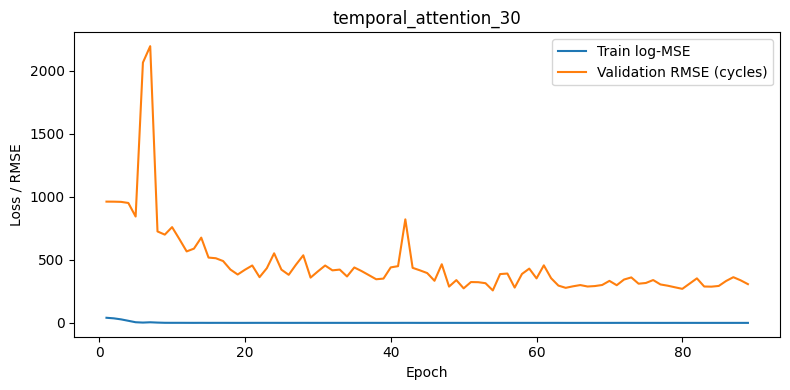

Saved temporal_attention_30: best epoch=54, validation RMSE=257.559

===== Temporal attention: 100 cycles =====
temporal_attention_100 epoch 1: val RMSE=961.699
temporal_attention_100 epoch 10: val RMSE=572.272
temporal_attention_100 epoch 20: val RMSE=356.746
temporal_attention_100 epoch 30: val RMSE=386.866
temporal_attention_100 epoch 40: val RMSE=341.532
temporal_attention_100 epoch 50: val RMSE=251.862
temporal_attention_100 epoch 60: val RMSE=304.831
temporal_attention_100 epoch 70: val RMSE=277.369
temporal_attention_100 epoch 80: val RMSE=318.711
Early stopping. Best epoch: 50


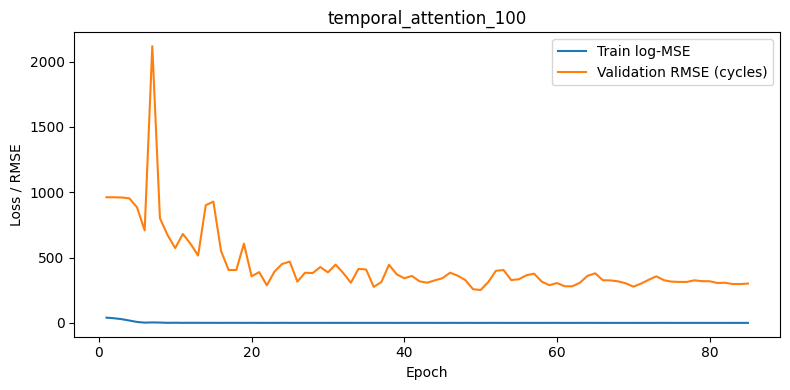

Saved temporal_attention_100: best epoch=50, validation RMSE=251.862


,model,horizon_cycles,MAE,RMSE,MAPE_percent,R2
0,Temporal attention CNN,10,149.669473,239.656185,16.494487,0.484863
1,Temporal attention CNN,30,136.145064,226.624111,14.672460,0.539364
2,Temporal attention CNN,100,177.786298,266.182335,21.000962,0.364517


In [10]:
attention_models, attention_rows = {}, []
for h in HORIZONS:
    print(f"\n===== Temporal attention: {h} cycles =====")
    model = train(TemporalAttentionCNN(DATA[h]["train"]["summary"].shape[-1]),
                  h, f"temporal_attention_{h}")
    attention_models[h] = model
    result = test_and_save(model, h, f"temporal_attention_{h}")
    attention_rows.append({"model":"Temporal attention CNN",
                           "horizon_cycles":h, **result})

attention_df = pd.DataFrame(attention_rows)
attention_df.to_csv(RESULT_ROOT / "temporal_attention_test_metrics.csv", index=False)
display(attention_df)

In [11]:
# Export per-cell, per-observed-cycle attention weights for interpretation.
for h, model in attention_models.items():
    model.eval()
    xd = torch.tensor(DATA[h]["test"]["delta"], dtype=torch.float32, device=DEVICE)
    xs = torch.tensor(DATA[h]["test"]["summary"], dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        _, weights = model(xd, xs, return_attention=True)
    weights = weights.cpu().numpy()
    rows = [{"sample_id":sid, "observed_cycle_position":j+1,
             "attention_weight":float(weights[i,j])}
            for i,sid in enumerate(DATA[h]["test"]["ids"])
            for j in range(weights.shape[1])]
    pd.DataFrame(rows).to_csv(
        RESULT_ROOT / f"temporal_attention_{h}_test_weights.csv", index=False)
print("Attention weights exported.")

Attention weights exported.


## 5. No-attention ablation

This model keeps the same temporal encoder and ΔQ(V) convolutional pathway, but replaces learned attention with uniform mean pooling. The comparison isolates the contribution of the attention mechanism.

In [12]:
class NoAttentionCNN(nn.Module):
    def __init__(self, n_summary=6):
        super().__init__()
        self.curve = nn.Sequential(
            nn.Conv1d(1,16,7,padding=3), nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16,32,5,padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32,64,3,padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten())
        self.encoder = nn.Sequential(nn.Linear(n_summary,32), nn.ReLU(),
                                     nn.Linear(32,64), nn.ReLU())
        self.head = nn.Sequential(nn.Linear(128,128), nn.ReLU(), nn.Dropout(.25),
                                  nn.Linear(128,32), nn.ReLU(), nn.Linear(32,1))
    def forward(self, delta, summary):
        a = self.curve(delta.unsqueeze(1))
        b = self.encoder(summary).mean(dim=1)
        return self.head(torch.cat([a,b], dim=1)).squeeze(1)


===== No-attention ablation: 10 cycles =====
no_attention_10 epoch 1: val RMSE=961.874
no_attention_10 epoch 10: val RMSE=706.980
no_attention_10 epoch 20: val RMSE=442.326
no_attention_10 epoch 30: val RMSE=561.101
no_attention_10 epoch 40: val RMSE=533.469
no_attention_10 epoch 50: val RMSE=453.222
no_attention_10 epoch 60: val RMSE=418.344
no_attention_10 epoch 70: val RMSE=360.776
no_attention_10 epoch 80: val RMSE=306.520
Early stopping. Best epoch: 53


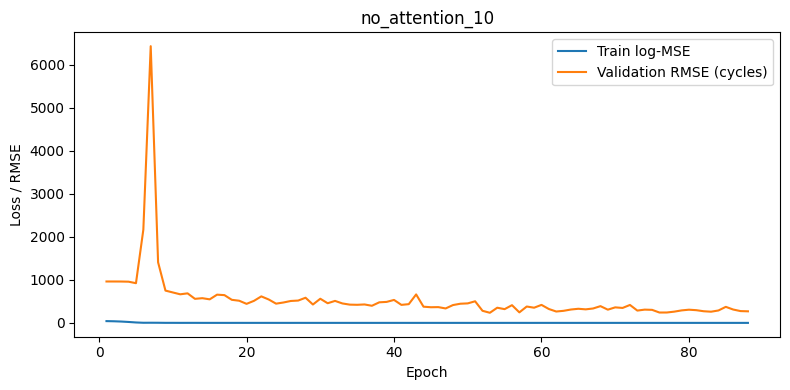

Saved no_attention_10: best epoch=53, validation RMSE=234.844

===== No-attention ablation: 30 cycles =====
no_attention_30 epoch 1: val RMSE=961.886
no_attention_30 epoch 10: val RMSE=690.094
no_attention_30 epoch 20: val RMSE=548.438
no_attention_30 epoch 30: val RMSE=414.517
no_attention_30 epoch 40: val RMSE=388.439
no_attention_30 epoch 50: val RMSE=322.203
no_attention_30 epoch 60: val RMSE=337.919
no_attention_30 epoch 70: val RMSE=364.545
no_attention_30 epoch 80: val RMSE=356.942
Early stopping. Best epoch: 48


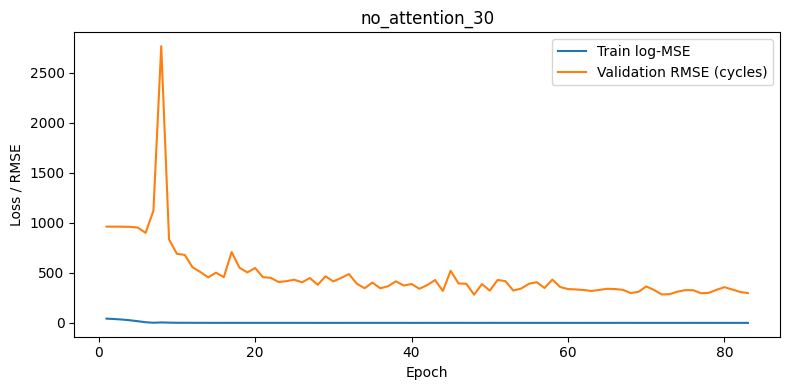

Saved no_attention_30: best epoch=48, validation RMSE=281.951

===== No-attention ablation: 100 cycles =====
no_attention_100 epoch 1: val RMSE=962.070
no_attention_100 epoch 10: val RMSE=505.911
no_attention_100 epoch 20: val RMSE=659.880
no_attention_100 epoch 30: val RMSE=378.958
no_attention_100 epoch 40: val RMSE=406.469
no_attention_100 epoch 50: val RMSE=257.419
no_attention_100 epoch 60: val RMSE=469.332
no_attention_100 epoch 70: val RMSE=269.644
no_attention_100 epoch 80: val RMSE=219.921
no_attention_100 epoch 90: val RMSE=309.222
no_attention_100 epoch 100: val RMSE=195.618
no_attention_100 epoch 110: val RMSE=193.115
no_attention_100 epoch 120: val RMSE=279.431
no_attention_100 epoch 130: val RMSE=233.837
no_attention_100 epoch 140: val RMSE=205.384
no_attention_100 epoch 150: val RMSE=233.572
no_attention_100 epoch 160: val RMSE=219.076
Early stopping. Best epoch: 127


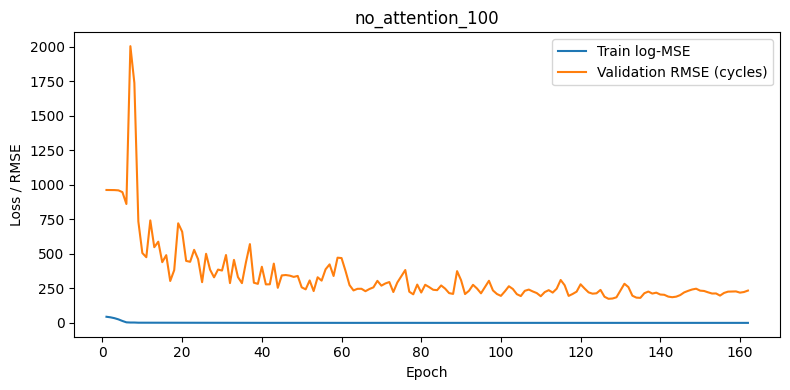

Saved no_attention_100: best epoch=127, validation RMSE=174.509


,model,horizon_cycles,MAE,RMSE,MAPE_percent,R2
0,No-attention ablation,10,170.964631,244.090534,20.043362,0.465623
1,No-attention ablation,30,144.108903,209.466762,17.068913,0.606472
2,No-attention ablation,100,133.432067,182.617223,16.982148,0.700891


In [13]:
ablation_models, ablation_rows = {}, []
for h in HORIZONS:
    print(f"\n===== No-attention ablation: {h} cycles =====")
    model = train(NoAttentionCNN(DATA[h]["train"]["summary"].shape[-1]),
                  h, f"no_attention_{h}")
    ablation_models[h] = model
    result = test_and_save(model, h, f"no_attention_{h}")
    ablation_rows.append({"model":"No-attention ablation",
                          "horizon_cycles":h, **result})

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(RESULT_ROOT / "no_attention_test_metrics.csv", index=False)
display(ablation_df)

## 6. CNN + Elastic-Net prediction fusion (optional)

This section loads the fitted Elastic-Net pipelines from `results/baselines/elastic_net_{horizon}.joblib` and combines their predictions with the corresponding 1D CNN predictions.

**Important methodological limitation:** the simple implementation below uses in-sample Elastic-Net predictions for the training cells because the baseline artifact is refitted on train + validation for baseline reporting. This can make the fusion head optimistic. For a publication-grade fusion result, generate out-of-fold Elastic-Net predictions for the training cells and train the fusion head on those instead. Run `baselines.ipynb` before this section.

In [14]:
class FusionHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2,16), nn.ReLU(), nn.Dropout(.15),
                                  nn.Linear(16,8), nn.ReLU(), nn.Linear(8,1))
    def forward(self, x): return self.net(x).squeeze(1)

def cnn_predictions(model, h, split):
    y, p = predict(model, loader(DATA[h][split]))
    return p.astype(np.float32)

def enet_predictions(h, split):
    path = BASELINE_ROOT / f"elastic_net_{h}.joblib"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run baselines.ipynb first.")
    model = joblib.load(path)
    return np.exp(np.clip(model.predict(DATA[h][split]["delta"]), -20, 20)).astype(np.float32)

In [15]:
fusion_rows = []
for h in HORIZONS:
    fusion_X = {}
    for split in SPLITS:
        fusion_X[split] = np.column_stack([
            cnn_predictions(cnn1d_models[h], h, split),
            enet_predictions(h, split)
        ]).astype(np.float32)

    Xtr = torch.tensor(fusion_X["train"], dtype=torch.float32)
    ytr = torch.tensor(np.log(DATA[h]["train"]["y"]), dtype=torch.float32)
    Xva = torch.tensor(fusion_X["val"], dtype=torch.float32, device=DEVICE)
    yva = DATA[h]["val"]["y"]

    ds = torch.utils.data.TensorDataset(Xtr, ytr)
    dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True)
    head = FusionHead().to(DEVICE)
    opt = torch.optim.Adam(head.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.MSELoss()
    best_state, best_rmse, patience = None, np.inf, 0

    for epoch in range(1,501):
        head.train()
        for xb,yb in dl:
            opt.zero_grad()
            loss = loss_fn(head(xb.to(DEVICE)), yb.to(DEVICE))
            loss.backward(); opt.step()
        head.eval()
        with torch.no_grad():
            pv = np.exp(np.clip(head(Xva).cpu().numpy(), -20, 20))
        score = metrics(yva, pv)["RMSE"]
        if score < best_rmse:
            best_rmse, best_state, patience = score, copy.deepcopy(head.state_dict()), 0
        else:
            patience += 1
        if patience >= 50: break

    head.load_state_dict(best_state)
    torch.save(head.state_dict(), RESULT_ROOT / f"fusion_cnn_enet_{h}.pth")
    Xte = torch.tensor(fusion_X["test"], dtype=torch.float32, device=DEVICE)
    head.eval()
    with torch.no_grad():
        pred = np.exp(np.clip(head(Xte).cpu().numpy(), -20, 20))
    ytest = DATA[h]["test"]["y"]
    result = metrics(ytest, pred)
    pd.DataFrame({"sample_id":DATA[h]["test"]["ids"], "y_true":ytest,
                  "y_pred":pred, "residual":ytest-pred}).to_csv(
        RESULT_ROOT / f"fusion_cnn_enet_{h}_test_predictions.csv", index=False)
    fusion_rows.append({"model":"CNN + Elastic-Net fusion",
                        "horizon_cycles":h, **result})

fusion_df = pd.DataFrame(fusion_rows)
fusion_df.to_csv(RESULT_ROOT / "fusion_test_metrics.csv", index=False)
display(fusion_df)

,model,horizon_cycles,MAE,RMSE,MAPE_percent,R2
0,CNN + Elastic-Net fusion,10,824.976361,996.208723,106.945796,-7.901160
1,CNN + Elastic-Net fusion,30,628.621642,969.078029,89.106674,-7.422934
2,CNN + Elastic-Net fusion,100,2097.683220,8150.920283,163.483027,-594.880538


## 7. Aggregate test metrics and bootstrap RMSE confidence intervals

Run after whichever model sections you completed. This reads saved prediction and metric files; it does not retrain models.

In [16]:
metric_names = ["cnn_1d_test_metrics.csv", "cnn_2d_test_metrics.csv",
                "temporal_attention_test_metrics.csv",
                "no_attention_test_metrics.csv", "fusion_test_metrics.csv"]
frames = [pd.read_csv(RESULT_ROOT/f) for f in metric_names
          if (RESULT_ROOT/f).exists()]
if frames:
    combined = pd.concat(frames, ignore_index=True)
    combined.to_csv(RESULT_ROOT / "all_deep_learning_test_metrics.csv", index=False)
    display(combined.sort_values(["horizon_cycles","model"]))
else:
    print("No model metric files found yet.")

def bootstrap_rmse_ci(y, p, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed); y=np.asarray(y); p=np.asarray(p); n=len(y)
    vals=[]
    for _ in range(n_boot):
        ix=rng.integers(0,n,n)
        vals.append(np.sqrt(mean_squared_error(y[ix],p[ix])))
    return np.percentile(vals,[2.5,97.5])

ci=[]
for path in RESULT_ROOT.glob("*_test_predictions.csv"):
    df=pd.read_csv(path)
    if {"y_true","y_pred"}.issubset(df.columns):
        lo,hi=bootstrap_rmse_ci(df.y_true,df.y_pred)
        ci.append({"file":path.name,"n_test":len(df),
                   "RMSE":np.sqrt(mean_squared_error(df.y_true,df.y_pred)),
                   "RMSE_CI_2.5":lo,"RMSE_CI_97.5":hi})
if ci:
    ci_df=pd.DataFrame(ci)
    ci_df.to_csv(RESULT_ROOT/"test_rmse_bootstrap_ci.csv",index=False)
    display(ci_df)

,model,horizon_cycles,MAE,RMSE,MAPE_percent,R2
0,1D CNN,10,186.730099,311.477791,20.318987,0.129838
10,CNN + Elastic-Net fusion,10,824.976361,996.208723,106.945796,-7.901160
7,No-attention ablation,10,170.964631,244.090534,20.043362,0.465623
4,Temporal attention CNN,10,149.669473,239.656185,16.494487,0.484863
1,1D CNN,30,112.181461,153.460604,14.373024,0.788778
11,CNN + Elastic-Net fusion,30,628.621642,969.078029,89.106674,-7.422934
8,No-attention ablation,30,144.108903,209.466762,17.068913,0.606472
5,Temporal attention CNN,30,136.145064,226.624111,14.672460,0.539364
2,1D CNN,100,162.930846,236.194481,20.311566,0.499637
3,2D CNN,100,226.940755,288.130965,33.543940,0.255395


,file,n_test,RMSE,RMSE_CI_2.5,RMSE_CI_97.5
0,cnn_1d_100_100_test_predictions.csv,29,236.194488,145.333923,318.700450
1,cnn_1d_10_10_test_predictions.csv,29,311.477791,157.875392,473.725837
2,cnn_1d_30_30_test_predictions.csv,29,153.460605,98.694662,200.102532
3,cnn_2d_100_100_test_predictions.csv,29,288.130965,195.630000,379.702887
4,fusion_cnn_enet_100_test_predictions.csv,29,8150.920313,541.142457,14088.973284
5,fusion_cnn_enet_10_test_predictions.csv,29,996.208721,697.776601,1342.161070
6,fusion_cnn_enet_30_test_predictions.csv,29,969.078035,474.293941,1522.165802
7,no_attention_100_100_test_predictions.csv,29,182.617231,111.955535,260.523916
8,no_attention_10_10_test_predictions.csv,29,244.090536,168.346343,308.082868
9,no_attention_30_30_test_predictions.csv,29,209.466765,130.188244,285.658140


## Output structure

`results/deep_learning/` contains model checkpoints (`.pth`), training histories, learning curves, test prediction CSVs, test metric summaries, attention-weight CSVs, and bootstrap confidence intervals.

**Core-only execution:** run the setup cells, then the 1D CNN and 2D CNN sections. You may skip the temporal-attention, no-attention, fusion, and aggregation sections if they are outside your required scope.